# Radial resolution $\delta q$ of a pixel-based integration: Pilatus1M demonstrator

Issue [#3006](https://github.com/silx-kit/pyFAI/issues/3006) — *Radial / azimuthal uncertainties*.

**Question:** when the pixels of a detector are binned in $q$, which uncertainty $\delta q$ should be attached to each point of the integrated curve?

**Idea:** the pixel centres collected in a bin are not located exactly on the bin centre. The root-mean-square (RMS) distance between pixel centres and the bin centre is a measure of $\delta q$. For a given geometry and mask, it does not depend on the intensity of the image.

This notebook uses **plain pyFAI and numpy, without any modification of the library**; it can be moved into the `AzimuthalIntegrator` later.

1. The image and its integrated curve
2. $\delta q$ without pixel splitting
3. $\delta q$ with full pixel splitting, and the effect of oversampling
4. Explicit calculation of the pixel resolution
5. Conclusion

In [1]:
import time
import numpy
from matplotlib import pyplot as plt
import pyFAI
from pyFAI.test.utilstest import UtilsTest
from pyFAI.integrator.azimuthal import AzimuthalIntegrator
from pyFAI.gui import jupyter
import fabio
start_time = time.perf_counter()
print("pyFAI", pyFAI.version)

pyFAI 2026.11.0-dev0


## 1. The image and its integrated curve

We use the `Pilatus1M.edf` image of the pyFAI test data, with its geometry (`Pilatus1M.poni`).
The mask is the one of the detector, completed with the invalid (negative) pixels of this image: $\delta q$ depends on which pixels are kept, so it must be computed with the same mask as the integration.

In [2]:
img = fabio.open(UtilsTest.getimage("Pilatus1M.edf")).data
ai = pyFAI.load(UtilsTest.getimage("Pilatus1M.poni"))
mask = ai.detector.mask | (img < 0)
print(ai)
print("image shape:", img.shape, "masked pixels:", int(mask.sum()))

Detector Pilatus 1M	 PixelSize= 172µm, 172µm	 BottomRight (3)	 Si,320µm
Wavelength= 1.000000 Å	Parallax: off
SampleDetDist= 1.583231e+00 m	PONI= 3.341702e-02, 4.122778e-02 m	rot1=0.006487  rot2=0.007558  rot3=0.000000 rad
DirectBeamDist= 1583.310 mm	Center: x=179.981, y=263.859 pix	Tilt= 0.571° tiltPlanRotation= 130.640° λ= 1.000Å
image shape: (1043, 981) masked pixels: 73578


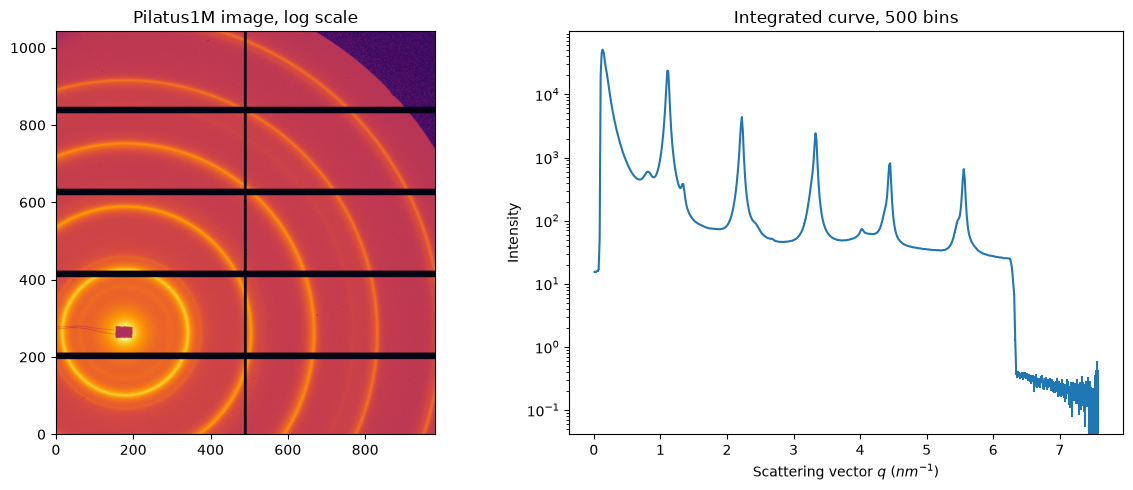

In [3]:
unit = "q_nm^-1"
npt = 500
res = ai.integrate1d(img, npt, unit=unit, mask=mask, method=("no", "histogram", "cython"), error_model="poisson")
q_bin = res.radial          # bin centres
count = res.count           # number of pixels per bin

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
jupyter.display(img, ax=ax[0])
ax[0].set_title("Pilatus1M image, log scale")
jupyter.plot1d(res, ax=ax[1])
ax[1].set_yscale("log")#; ax[1].set_xlabel("q ($nm^{-1}$)"); ax[1].set_ylabel("I (a.u.)")
ax[1].set_title(f"Integrated curve, {npt} bins")
plt.tight_layout(); plt.show()

## 2. $\delta q$ without pixel splitting

Hypothesis: no pixel splitting. Each pixel contributes entirely to the bin that contains its centre. For a bin $b$ made of $N_b$ pixels:

$$\delta q_{b} = \sqrt{\frac{1}{N_{b}}\sum_{i\in b} (q_i - q_{b})^2}$$

where $q_i$ is the position of the pixel centre and $q_b$ the centre of the bin. The calculation needs three steps:

1. get the $q$ of each pixel centre (`center_array`);
2. re-create the bin assignment of the "no splitting / histogram" method, `floor((q - q_min)/step)`, with the same bin edges as the integrator;
3. accumulate $\sum (q_i - q_{b})^2$ and $N_b$ per bin with `numpy.bincount`.

In [4]:
def edges_of(radial):
    "Outer bin edges deduced from the regularly spaced bin centres"
    half = (radial[1] - radial[0]) / 2
    return radial[0] - half, radial[-1] + half


def delta_q(ai, shape, npt, radial_range, mask=None, unit="q_nm^-1"):
    """RMS distance between pixel centres and bin centres, per radial bin.

    :return: bin centres, deltaQ (same unit), pixel count per bin
    """
    q = ai.center_array(shape, unit=unit)
    valid = numpy.ones(shape, dtype=bool) if mask is None else (mask == 0)
    lo, hi = radial_range
    step = (hi - lo) / npt
    idx = numpy.floor((q - lo) / step).astype(int)
    valid &= (idx >= 0) & (idx < npt)
    idx = idx[valid]
    centers = lo + (numpy.arange(npt) + 0.5) * step
    d2 = (q[valid] - centers[idx]) ** 2
    count = numpy.bincount(idx, minlength=npt)
    sum_d2 = numpy.bincount(idx, weights=d2, minlength=npt)
    with numpy.errstate(invalid="ignore", divide="ignore"):
        dq = numpy.sqrt(sum_d2 / count)
    dq[count == 0] = numpy.nan
    return centers, dq, count

centers, dq, cnt = delta_q(ai, img.shape, npt, edges_of(q_bin), mask=mask, unit=unit)
step = centers[1] - centers[0]

Check that our binning is consistent with pyFAI: same bin centres and same number of pixels per bin.

In [5]:
print("max |centre difference| :", numpy.nanmax(abs(centers - q_bin)))
print("pixels per bin identical :", numpy.array_equal(cnt, numpy.round(count).astype(int)))
print("total counted:", cnt.sum(), "vs", int(count.sum()))

max |centre difference| : 8.881784197001252e-16
pixels per bin identical : True
total counted: 949605 vs 949605


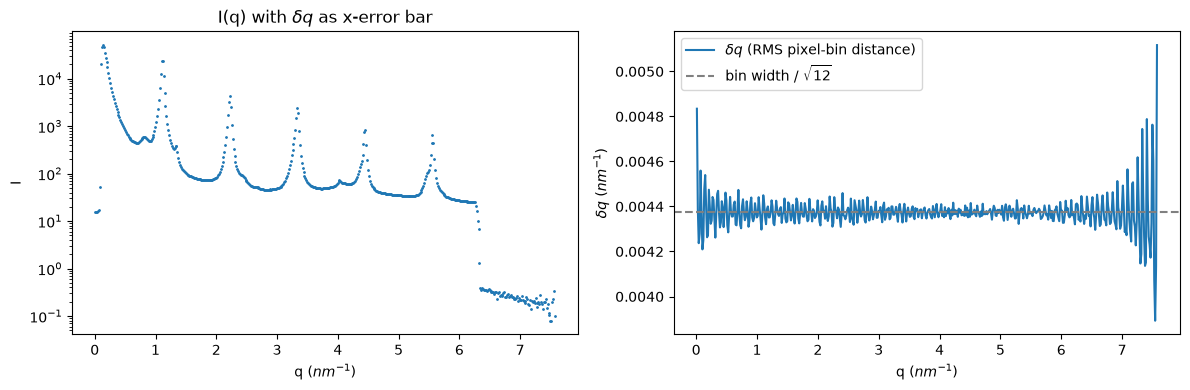

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].errorbar(q_bin, res.intensity, xerr=dq, fmt=".", ms=2, elinewidth=0.5)
ax[0].set_yscale("log"); ax[0].set_xlabel("q ($nm^{-1}$)"); ax[0].set_ylabel("I"); ax[0].set_title("I(q) with $\\delta q$ as x-error bar")
ax[1].plot(centers, dq, label="$\\delta q$ (RMS pixel-bin distance)")
ax[1].axhline(step / numpy.sqrt(12), color="gray", ls="--", label="bin width / $\\sqrt{12}$")
ax[1].set_xlabel("q ($nm^{-1}$)"); ax[1].set_ylabel("$\\delta q$ ($nm^{-1}$)"); ax[1].legend()
plt.tight_layout(); plt.show()

When a bin holds many pixels spread uniformly across it, $\delta q \to$ bin width $/\sqrt{12}$ (uniform distribution, dashed line): without splitting, $\delta q$ is given by the binning alone. Let's check how it scales with the number of bins.

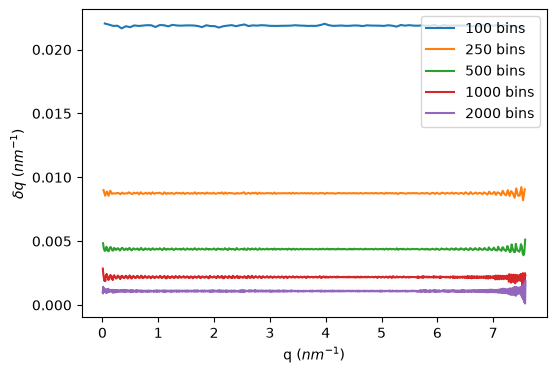

In [7]:
plt.figure(figsize=(6, 4))
for n in (100, 250, 500, 1000, 2000):
    r = ai.integrate1d(img, n, unit=unit, mask=mask, method=("no", "histogram", "cython"))
    c, d, _ = delta_q(ai, img.shape, n, edges_of(r.radial), mask=mask, unit=unit)
    plt.plot(c, d, label=f"{n} bins")
plt.xlabel("q ($nm^{-1}$)"); plt.ylabel("$\\delta q$ ($nm^{-1}$)"); plt.legend(); plt.show()

## 3. $\delta q$ with full pixel splitting, and the effect of oversampling

### 3.1 Definition

With `("full", "csr", "cython")` a pixel is cut along the bin edges and shares its signal between all the bins it overlaps, with weights $w_{ib}$ proportional to the overlap area.
The sparse matrix of the CSR engine holds exactly those weights, so the demonstrator can read them with no change to pyFAI.
The weighted RMS generalises the previous definition:

$$\delta q_{b} = \sqrt{\frac{\sum_i w_{ib}\,(x_{ib} - q_{b})^2}{\sum_i w_{ib}}}$$

where $x_{ib}$ is the position of the contribution of pixel $i$ to bin $b$. Two choices are compared:

* **centre**: $x_{ib}=q_i$, the pixel centre (the exact analogue of section 2). A pixel straddling two bins counts as *one displacement* in each.
* **fragment**: $x_{ib}$ is the centre of the part of the pixel falling inside the bin, i.e. the position of the signal actually put in the bin. The pixel footprint along $q$ is approximated by the interval $q_i\pm h_i$ ($h_i$ from `delta_array`); the weights remain the exact ones of the engine.

In [8]:
# same bin edges as the no-split integration (by default the range is wider with splitting: pixels have an extent)
res_full = ai.integrate1d(img, npt, unit=unit, mask=mask, radial_range=edges_of(q_bin), method=("full", "csr", "cython"))
eng = ai.engines[res_full.method].engine           # the CSR engine just used
print("same bin centres as no-split:", numpy.allclose(res_full.radial, q_bin))

w = numpy.asarray(eng.data, dtype=numpy.float64)        # weights (pixel fraction in the bin)
pix = numpy.asarray(eng.indices)                        # flat pixel index
ptr = numpy.asarray(eng.indptr)
bin_of = numpy.repeat(numpy.arange(npt), numpy.diff(ptr))  # bin index of every non-zero entry
print("non-zero entries:", w.size, "; mean bins per pixel:", w.size / numpy.unique(pix).size)

same bin centres as no-split: True
non-zero entries: 1489973 ; mean bins per pixel: 1.5690450239836564


In [9]:
def delta_q_split(ai, shape, w, pix, bin_of, edges, npt, unit="q_nm^-1"):
    """Weighted RMS displacement from the CSR sparse matrix of a splitting engine.

    :return: dq_centre, dq_fragment, sum of the weights per bin
    """
    lo, hi = edges
    step = (hi - lo) / npt
    centers = lo + (numpy.arange(npt) + 0.5) * step
    q = ai.center_array(shape, unit=unit).ravel()[pix]
    h = ai.array_from_unit(shape, "delta", unit, scale=True).ravel()[pix]
    # fragment = intersection of the pixel interval and of the bin
    a = numpy.maximum(q - h, lo + bin_of * step)
    b = numpy.minimum(q + h, lo + (bin_of + 1) * step)
    frag = numpy.where(b > a, 0.5 * (a + b), q)
    sw = numpy.bincount(bin_of, weights=w, minlength=npt)
    out = []
    for x in (q, frag):
        s2 = numpy.bincount(bin_of, weights=w * (x - centers[bin_of]) ** 2, minlength=npt)
        with numpy.errstate(invalid="ignore", divide="ignore"):
            out.append(numpy.sqrt(s2 / sw))
    return out[0], out[1], sw

dq_c, dq_f, sw = delta_q_split(ai, img.shape, w, pix, bin_of, edges_of(q_bin), npt, unit=unit)
print("effective number of pixels per bin, no-split vs split:", cnt[250], sw[250])

effective number of pixels per bin, no-split vs split: 2827 2827.0113164398726


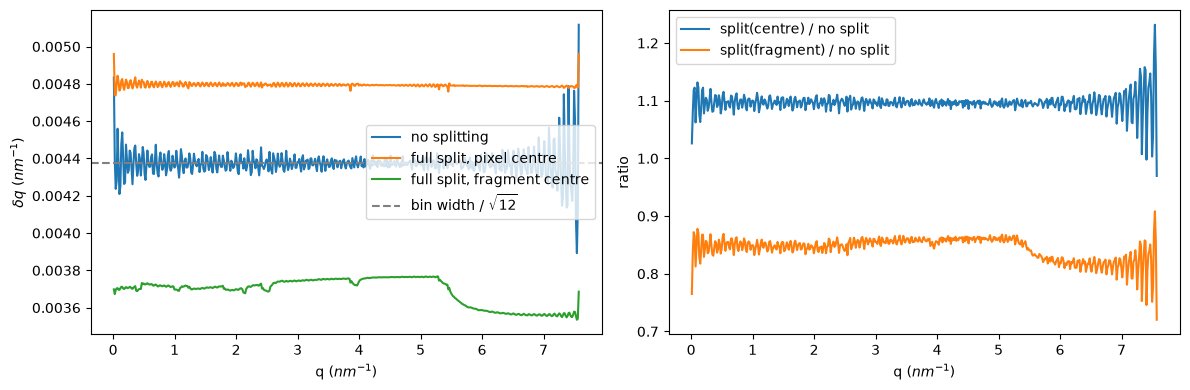

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(centers, dq, label="no splitting")
ax[0].plot(centers, dq_c, label="full split, pixel centre")
ax[0].plot(centers, dq_f, label="full split, fragment centre")
ax[0].axhline(step / numpy.sqrt(12), color="gray", ls="--", label="bin width / $\\sqrt{12}$")
ax[0].set_xlabel("q ($nm^{-1}$)"); ax[0].set_ylabel("$\\delta q$ ($nm^{-1}$)"); ax[0].legend()
ax[1].plot(centers, dq_c / dq, label="split(centre) / no split")
ax[1].plot(centers, dq_f / dq, label="split(fragment) / no split")
ax[1].set_xlabel("q ($nm^{-1}$)"); ax[1].set_ylabel("ratio"); ax[1].legend()
plt.tight_layout(); plt.show()

With 500 bins, the *centre* estimate is about 9% above the no-splitting one, since pixels centred in a neighbouring bin contribute with a large displacement even if only a small part of them lies in the bin.
The *fragment* estimate stays below bin width/$\sqrt{12}$ since each fragment lies inside the bin: it reports only the genuine in-bin spread.

### 3.2 Oversampling: is there an optimum for $\delta q$ ?

We now push the number of bins up to 5000 (bins much narrower than a pixel), with **full splitting** and the displacement measured from the **pixel centre**.
For each number of bins we take the median of $\delta q$ over the radial range.
Expected behaviour: $\delta q^2 \approx \Delta q^2/12 + \sigma_{pix}^2$, a binning term plus a floor $\sigma_{pix}$ from the size of the pixels, which does not depend on the binning.

In [11]:
npts = [100, 250, 500, 750, 1000, 1500, 2000, 3000, 4000, 5000]
rng = edges_of(q_bin)
scan = {}
for n in npts:
    r = ai.integrate1d(img, n, unit=unit, mask=mask, radial_range=rng, method=("full", "csr", "cython"))
    e = ai.engines[r.method].engine
    ww, pp, ii = numpy.asarray(e.data, dtype=numpy.float64), numpy.asarray(e.indices), numpy.asarray(e.indptr)
    bb = numpy.repeat(numpy.arange(n), numpy.diff(ii))
    c, f, _ = delta_q_split(ai, img.shape, ww, pp, bb, rng, n, unit=unit)
    scan[n] = (c, f, (rng[1] - rng[0]) / n, ww.size)
    del ww, pp, bb, e
steps = numpy.array([scan[n][2] for n in npts])
dq_centre = numpy.array([numpy.nanmedian(scan[n][0]) for n in npts])
dq_frag = numpy.array([numpy.nanmedian(scan[n][1]) for n in npts])
# fit  dq^2 = a * step^2/12 + sigma^2   (a=1 expected)
A = numpy.vstack([steps**2 / 12, numpy.ones_like(steps)]).T
(a, sig2), *_ = numpy.linalg.lstsq(A, dq_centre**2, rcond=None)
sigma_fit = numpy.sqrt(sig2)
print(f"fit: dq^2 = {a:.3f} * step^2/12 + sigma^2, sigma_pix = {sigma_fit:.5f} nm^-1")
for n, st, d, f in zip(npts, steps, dq_centre, dq_frag):
    print(f"{n:5d} bins  step={st:.5f}  dq(centre)={d:.5f}  dq(fragment)={f:.5f}")

fit: dq^2 = 1.000 * step^2/12 + sigma^2, sigma_pix = 0.00196 nm^-1
  100 bins  step=0.07576  dq(centre)=0.02196  dq(fragment)=0.02171
  250 bins  step=0.03030  dq(centre)=0.00897  dq(fragment)=0.00837
  500 bins  step=0.01515  dq(centre)=0.00479  dq(fragment)=0.00371
  750 bins  step=0.01010  dq(centre)=0.00351  dq(fragment)=0.00206
 1000 bins  step=0.00758  dq(centre)=0.00293  dq(fragment)=0.00127
 1500 bins  step=0.00505  dq(centre)=0.00244  dq(fragment)=0.00062
 2000 bins  step=0.00379  dq(centre)=0.00224  dq(fragment)=0.00037
 3000 bins  step=0.00253  dq(centre)=0.00209  dq(fragment)=0.00017
 4000 bins  step=0.00189  dq(centre)=0.00203  dq(fragment)=0.00010
 5000 bins  step=0.00152  dq(centre)=0.00201  dq(fragment)=0.00006


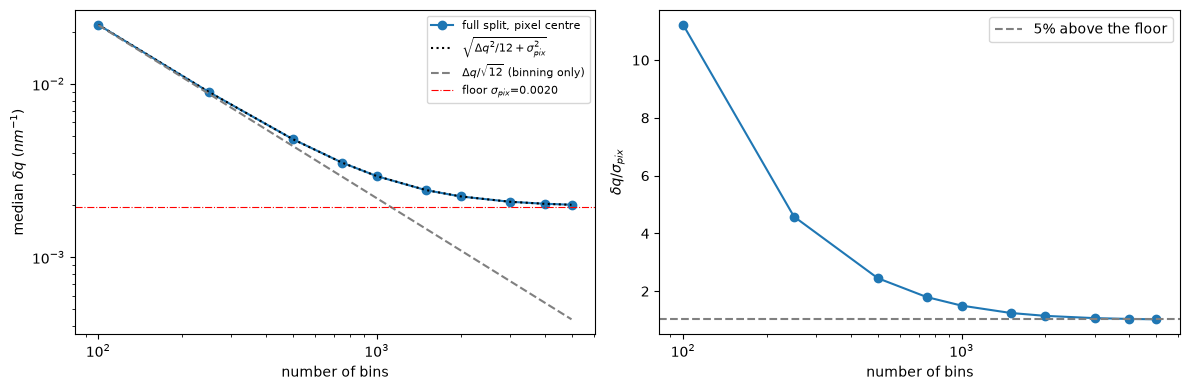

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(npts, dq_centre, "o-", label="full split, pixel centre")
ax[0].loglog(npts, numpy.sqrt(steps**2 / 12 + sigma_fit**2), "k:", label="$\\sqrt{\\Delta q^2/12+\\sigma_{pix}^2}$")
ax[0].loglog(npts, steps / numpy.sqrt(12), "--", color="gray", label="$\\Delta q/\\sqrt{12}$ (binning only)")
ax[0].axhline(sigma_fit, color="red", ls="-.", lw=0.8, label=f"floor $\\sigma_{{pix}}$={sigma_fit:.4f}")
ax[0].set_xlabel("number of bins"); ax[0].set_ylabel("median $\\delta q$ ($nm^{-1}$)"); ax[0].legend(fontsize=8)
ax[1].semilogx(npts, dq_centre / sigma_fit, "o-")
ax[1].axhline(1.05, color="gray", ls="--", label="5% above the floor")
ax[1].set_xlabel("number of bins"); ax[1].set_ylabel("$\\delta q/\\sigma_{pix}$"); ax[1].legend()
plt.tight_layout(); plt.show()

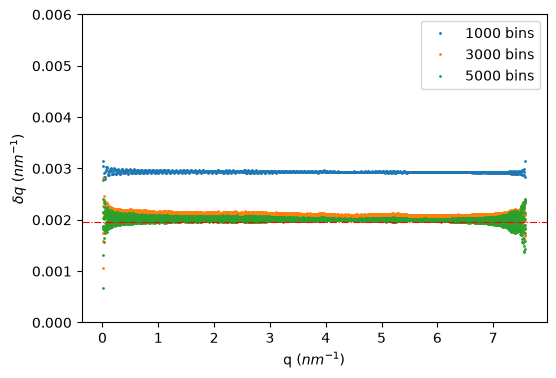

In [13]:
# Is the floor independent of q ?
plt.figure(figsize=(6, 4))
for n in (1000, 3000, 5000):
    c = scan[n][0]
    plt.plot(rng[0] + (numpy.arange(n) + 0.5) * scan[n][2], c, ".", ms=2, label=f"{n} bins")
plt.axhline(sigma_fit, color="red", ls="-.", lw=0.8)
plt.xlabel("q ($nm^{-1}$)"); plt.ylabel("$\\delta q$ ($nm^{-1}$)"); plt.legend(); plt.ylim(0, 0.006); plt.show()

### Conclusion of the pixel-splitting part

* There is **no optimum for the number of bins**: with full splitting and a displacement measured from the pixel centre, $\delta q$ decreases monotonically with the number of bins and saturates on a floor $\sigma_{pix}$ given by the pixel size, independent of the binning. The fit coefficient of $\Delta q^2/12$ is 1.00, i.e. the model is right.
* **Oversampling is of no interest beyond the resolution of the pixel**: once the bin width reaches the footprint of a pixel in $q$, finer bins only reduce the binning term. A pixel then feeds many neighbouring bins (about 7 on average at 5000 bins), which become strongly correlated; the sparse matrix grows linearly with the number of bins (6.4M non-zeros at 5000 bins against 1.5M at 500) while the information does not improve.
* The *fragment* definition keeps falling toward 0 with narrower bins, simply because the fragment is confined to an ever narrower bin: it does not measure the resolution of the instrument and should not be used to look for an optimum.

The next section computes the floor explicitly.

## 4. Explicit calculation of the pixel resolution

The floor can be computed without any integration, from the geometry only.
Around its centre $q_i$, a pixel extends in $q$ over its footprint. To first order $q$ is linear on the pixel, with the gradient $\nabla q$ expressed per pixel (`numpy.gradient` of the $q$ array):

$$q(x,y) \approx q_i + g_x\,x + g_y\,y,\qquad x,y\in[-\tfrac12,\tfrac12]\ \text{pixel}$$

* the footprint width along $q$ is $w_{pix} = |\nabla q| = \sqrt{g_x^2+g_y^2}$;
* for a uniform pixel, $\langle x^2\rangle=\langle y^2\rangle=1/12$, hence the variance of the footprint is $s_i^2=(g_x^2+g_y^2)/12$;
* with infinitely narrow bins, the pixels of a bin are weighted by their overlap, and $\delta q^2$ is the mean of $s_i^2$ over the pixels of the bin:

$$\sigma_{pix}^2(q) = \frac{\langle |\nabla q|^2\rangle}{12},\qquad \Delta q_{knee} = w_{pix} = \sqrt{12}\,\sigma_{pix}$$

$\Delta q_{knee}$ is the bin width at which the binning term equals the pixel term: it gives the useful number of bins.

In [14]:
q_pix = ai.center_array(img.shape, unit=unit)
g0, g1 = numpy.gradient(q_pix)                 # change of q per pixel along the two axes
w_pix = numpy.sqrt(g0 ** 2 + g1 ** 2)          # footprint of a pixel along q
valid = mask == 0

sigma_pix = numpy.sqrt(numpy.mean(w_pix[valid] ** 2) / 12)
q_lo, q_hi = rng
dq_knee = numpy.sqrt(12) * sigma_pix
print(f"mean footprint of a pixel in q : {w_pix[valid].mean():.5f} nm^-1")
print(f"sigma_pix (explicit)           : {sigma_pix:.5f} nm^-1")
print(f"sigma_pix (fit of section 3.2) : {sigma_fit:.5f} nm^-1")
print(f"knee: bin width {dq_knee:.5f} nm^-1 -> {(q_hi - q_lo) / dq_knee:.0f} bins over [{q_lo:.3f}, {q_hi:.3f}] nm^-1")

mean footprint of a pixel in q : 0.00680 nm^-1
sigma_pix (explicit)           : 0.00196 nm^-1
sigma_pix (fit of section 3.2) : 0.00196 nm^-1
knee: bin width 0.00680 nm^-1 -> 1115 bins over [0.004, 7.580] nm^-1


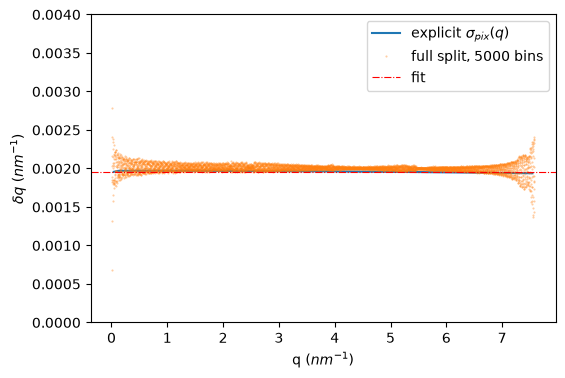

In [15]:
# dependence on q: ring average of the explicit calculation, compared to the floor of the scans
nb = 100
idx = numpy.clip(numpy.floor((q_pix - q_lo) / (q_hi - q_lo) * nb).astype(int), 0, nb - 1)
ring_s2 = numpy.bincount(idx[valid], weights=w_pix[valid] ** 2 / 12, minlength=nb) / numpy.bincount(idx[valid], minlength=nb)
plt.figure(figsize=(6, 4))
plt.plot(q_lo + (numpy.arange(nb) + 0.5) * (q_hi - q_lo) / nb, numpy.sqrt(ring_s2), label="explicit $\\sigma_{pix}(q)$")
plt.plot(rng[0] + (numpy.arange(5000) + 0.5) * scan[5000][2], scan[5000][0], ".", ms=1, alpha=0.4, label="full split, 5000 bins")
plt.axhline(sigma_fit, color="red", ls="-.", lw=0.8, label="fit")
plt.xlabel("q ($nm^{-1}$)"); plt.ylabel("$\\delta q$ ($nm^{-1}$)"); plt.ylim(0, 0.004); plt.legend(); plt.show()

## 5. Conclusion

For the Pilatus1M test image (172 µm pixels, 1.58 m, 1 Å):

* **The radial resolution limit of the pixels is $\sigma_{pix} = 0.00196\ nm^{-1}$**, found twice: by a fit of the oversampling scan ($0.00196$, section 3.2) and by the explicit geometric calculation $\sqrt{\langle|\nabla q|^2\rangle/12}$ ($0.00196$, section 4).
* A pixel covers $w_{pix}=0.0068\ nm^{-1}$ in $q$ ($=\sqrt{12}\,\sigma_{pix}$). The useful binning is therefore **about 1100 bins** over the $[0.004, 7.58]\ nm^{-1}$ range: the binning term then equals the pixel term and $\delta q\approx\sqrt{2}\,\sigma_{pix}\approx 0.0028\ nm^{-1}$.
* Without pixel splitting, $\delta q$ is given by the binning alone ($\Delta q/\sqrt{12}$): it is the lower bound of what the integrator can resolve only for bins larger than a pixel.
* With full splitting there is no optimum number of bins: $\delta q$ decreases down to $0.00196\ nm^{-1}$, and oversampling (3000 to 5000 bins) brings less than 10% (from $0.00224$ at 2000 bins to $0.00201$ at 5000 bins) while producing correlated bins and a matrix 4 times larger.

**A $\delta q$ column attached to an integrated curve should therefore be computed from the pixel-centre definition, $\delta q=\sqrt{\Delta q^2/12+\sigma_{pix}^2}$, with $\sigma_{pix}\approx 0.002\ nm^{-1}$ here; this value depends on the pixel size, the distance, the wavelength and the tilt, and is computed from the geometry alone.**


**Next steps (integration in pyFAI).**
* Without splitting, $\delta q$ needs only the pixel radial array, the mask and the bin edges: it fits in the histogram engines (Python, Cython, OpenCL) as one more accumulator, $\sum(q_i-q_b)^2$, next to the existing sums.
* For splitting engines the weights $w_{ib}$ are already stored in the sparse matrix: the same accumulators can be filled while the matrix is built.
* Since the pixel term is a pure geometry quantity, $\sigma_{pix}(q)=\sqrt{\langle|\nabla q|^2\rangle/12}$ can also be given directly, without any accumulator.
* The result would be exposed on `Integrate1dResult` (e.g. `sigma_radial`), and the same approach applies to $\chi$ in 2D (`deltaChi`).
* Open question: reference to the nominal bin centre (used here) or to the mean $q$ of the pixels of the bin.

In [16]:
print(f"Execution time: {time.perf_counter()-start_time:.3f}s")

Execution time: 11.237s
